### Required Assignment 5.1: Will the Customer Accept the Coupon?

**Context**

Imagine driving through town and a coupon is delivered to your cell phone for a restaurant near where you are driving. Would you accept that coupon and take a short detour to the restaurant? Would you accept the coupon but use it on a subsequent trip? Would you ignore the coupon entirely? What if the coupon was for a bar instead of a restaurant? What about a coffee house? Would you accept a bar coupon with a minor passenger in the car? What about if it was just you and your partner in the car? Would weather impact the rate of acceptance? What about the time of day?

Obviously, proximity to the business is a factor on whether the coupon is delivered to the driver or not, but what are the factors that determine whether a driver accepts the coupon once it is delivered to them? How would you determine whether a driver is likely to accept a coupon?

**Overview**

The goal of this project is to use what you know about visualizations and probability distributions to distinguish between customers who accepted a driving coupon versus those that did not.

**Data**

This data comes to us from the UCI Machine Learning repository and was collected via a survey on Amazon Mechanical Turk. The survey describes different driving scenarios including the destination, current time, weather, passenger, etc., and then ask the person whether he will accept the coupon if he is the driver. Answers that the user will drive there ‘right away’ or ‘later before the coupon expires’ are labeled as ‘Y = 1’ and answers ‘no, I do not want the coupon’ are labeled as ‘Y = 0’.  There are five different types of coupons -- less expensive restaurants (under \$20), coffee houses, carry out & take away, bar, and more expensive restaurants (\$20 - $50).

**Deliverables**

Your final product should be a brief report that highlights the differences between customers who did and did not accept the coupons.  To explore the data you will utilize your knowledge of plotting, statistical summaries, and visualization using Python. You will publish your findings in a public facing github repository as your first portfolio piece.





### Data Description
Keep in mind that these values mentioned below are average values.

The attributes of this data set include:
1. User attributes
    -  Gender: male, female
    -  Age: below 21, 21 to 25, 26 to 30, etc.
    -  Marital Status: single, married partner, unmarried partner, or widowed
    -  Number of children: 0, 1, or more than 1
    -  Education: high school, bachelors degree, associates degree, or graduate degree
    -  Occupation: architecture & engineering, business & financial, etc.
    -  Annual income: less than \\$12500, \\$12500 - \\$24999, \\$25000 - \\$37499, etc.
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she buys takeaway food: 0, less than 1, 1 to 3, 4 to 8 or greater
    than 8
    -  Number of times that he/she goes to a coffee house: 0, less than 1, 1 to 3, 4 to 8 or
    greater than 8
    -  Number of times that he/she eats at a restaurant with average expense less than \\$20 per
    person: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    -  Number of times that he/she goes to a bar: 0, less than 1, 1 to 3, 4 to 8 or greater than 8
    

2. Contextual attributes
    - Driving destination: home, work, or no urgent destination
    - Location of user, coupon and destination: we provide a map to show the geographical
    location of the user, destination, and the venue, and we mark the distance between each
    two places with time of driving. The user can see whether the venue is in the same
    direction as the destination.
    - Weather: sunny, rainy, or snowy
    - Temperature: 30F, 55F, or 80F
    - Time: 10AM, 2PM, or 6PM
    - Passenger: alone, partner, kid(s), or friend(s)


3. Coupon attributes
    - time before it expires: 2 hours or one day

In [44]:
#Loads all libraries needed for this assignment
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

### Problems

Use the prompts below to get started with your data analysis.  

1. Read in the `coupons.csv` file.




In [45]:
#Read CSV and load into a DataFrame
data = pd.read_csv('data/coupons.csv')

In [46]:
#Display top 5 rows from the "data" dataframe
data.head()

,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


2. Investigate the dataset for missing or problematic data.

In [47]:
#Before starting investigation on the missing and problematic data, printing a concise summary of the "data" dataFrame to understand the columns, data types and count of records in each column
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  car                   108 non-null    object
 15  Bar                   12577 non-null

In [48]:
#Printing the shape of the DataFrame to understand the how many rows and columns are present in the "data" dataframe

#print total rows in the dataset
Total_Rows = data.shape[0]
print(f'Total Rows: {Total_Rows}')
#print total collumns in the dataset
Total_Columns = data.shape[1]
print(f'Total Columns: {Total_Columns}')

Total Rows: 12684
Total Columns: 26


# **# Missing Data**
Goal is to identify what data is missing so that we can appropriate actions to improve data quality.

In [49]:
#Identify what columns contain null values and by how much percentage.

#Below code creates a new Dataframe called "null_record_summary" using existing "data" dataframe and stores count of null values in columns and the percentage of the null values against total rows.
null_record_summary = pd.DataFrame({'missing_count' : data.isnull().sum().sort_values(ascending=False),
                                    'missing_count_percentage' : (data.isnull().mean() * 100).round(2)})
null_record_summary = null_record_summary[null_record_summary['missing_count'] > 0].sort_values('missing_count', ascending=False)
print(null_record_summary)

                      missing_count  missing_count_percentage
car                           12576                     99.15
CoffeeHouse                     217                      1.71
Restaurant20To50                189                      1.49
CarryAway                       151                      1.19
RestaurantLessThan20            130                      1.02
Bar                             107                      0.84


**Plot a visualization that can demonstrate how null values are compare in all 6 columns thats missing data**

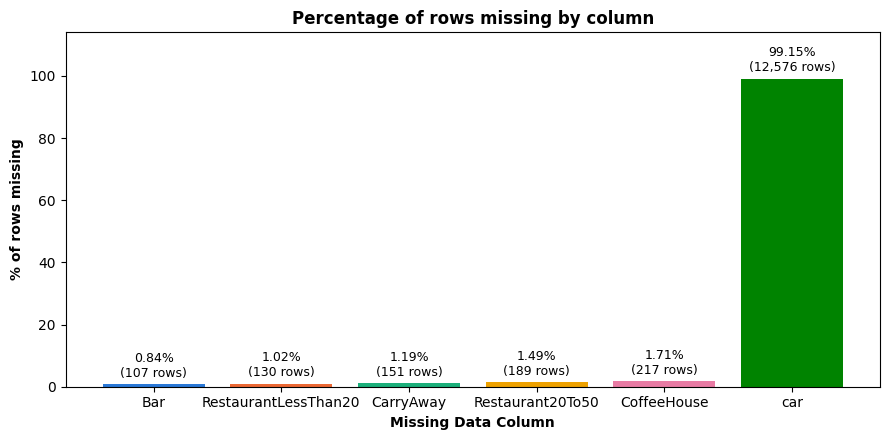

In [50]:
#Below code will plot the missing values in a bar graph.
plot_df = null_record_summary.sort_values('missing_count_percentage')
colors = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']   # one colour per column
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(plot_df.index, plot_df['missing_count_percentage'], color=colors[:len(plot_df)])
ax.bar_label(bars,
             labels=[f"{p:.2f}%\n({c:,} rows)" for p, c in
                     zip(plot_df['missing_count_percentage'], plot_df['missing_count'])],
             padding=3, fontsize=9)
ax.set_xlabel('Missing Data Column', fontweight='bold')
ax.set_ylabel('% of rows missing', fontweight='bold')
ax.set_ylim(0, plot_df['missing_count_percentage'].max() * 1.15)
ax.set_title('Percentage of rows missing by column', loc='center', fontweight='bold')
plt.tight_layout()
plt.savefig('images/data_missing_values_count_plot.png')
plt.show()

**`Findings:`**

*   Only 6 of 26 columns have gaps
*   car is missing data for 12,576 of 12,684 rows (99.15%). So, if the column is dropped, there won't be any impact and it will improve the data quality
*   The remaining 5 columns (CoffeeHouse, Restaurant20To50, CarryAway, RestaurantLessThan20 and Bar) are missing data between 0.84 % and 1.71%. This is a small percentage gap and the valules can be substituted without compromising the data quality.

*   The second column is named as "Passanger" instead of "Passenger".


# **Problematic Data:**

In [51]:
#Identify how many records are duplicate rows
duplicate_rows = data[data.duplicated()]
print(f'Total Duplicate Rows: {duplicate_rows.shape[0]}')

Total Duplicate Rows: 74


`Findings`


*   Duplicate Records: There are 74 duplicate rows in the dataset. The data doesn't have an identifier that specifically outlines that the records are unique. it is possible that two people that submitted responses have similar profile or present similar characteristics.



3. Decide what to do about your missing data -- drop, replace, other...

**Cleanup Actions**

*   Duplicate Records: Dropping these records from the dataset doesn't improve missing data quality sharply. So, we are going to assume that the 74 duplicate rows are indeed genuine records.  
*   Drop "car" column since 99.15% users do not have the data.
*   Replace missing data using "Mode" in columns remaining 5 columns (CoffeeHouse, Restaurant20To50, CarryAway, RestaurantLessThan20 and Bar). "Mean" is not an appropriate choice because the data in these columns is not numeric in nature. "Median" is not appropriate either because it provides a value which is at the middle. Instead, Mode will be able to substitute the missing data with the most frequent value that appeared in the dataset.






**Drop "car" column:**

In [52]:
#Drop "car" column from "data" and assign to a new DataFrame named "cleaned_data". axis = 1 tells pandas to look for column instead of rows.
cleaned_data = data.drop(columns=['car'], axis = 1)
#validate "car" column is dropped using info()
cleaned_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passanger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  Bar                   12577 non-null  object
 15  CoffeeHouse           12467 non-null

**Rename "Passanger" column to "Passenger"**

In [53]:
#rename "passanger" column to "passenger"
cleaned_data = cleaned_data.rename(columns={'passanger': 'passenger'})
#validate that the renaming is successful
cleaned_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12684 entries, 0 to 12683
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   destination           12684 non-null  object
 1   passenger             12684 non-null  object
 2   weather               12684 non-null  object
 3   temperature           12684 non-null  int64 
 4   time                  12684 non-null  object
 5   coupon                12684 non-null  object
 6   expiration            12684 non-null  object
 7   gender                12684 non-null  object
 8   age                   12684 non-null  object
 9   maritalStatus         12684 non-null  object
 10  has_children          12684 non-null  int64 
 11  education             12684 non-null  object
 12  occupation            12684 non-null  object
 13  income                12684 non-null  object
 14  Bar                   12577 non-null  object
 15  CoffeeHouse           12467 non-null

**Replace null values in remaning 5 columns with "Mode":**

In [54]:
# Replace missing values for the 5 columns (CoffeeHouse, Restaurant20To50, CarryAway, RestaurantLessThan20 and Bar) with "Mode" value
missing_data_columns = ['CoffeeHouse', 'Restaurant20To50', 'CarryAway', 'RestaurantLessThan20', 'Bar']
for column in missing_data_columns:
  cleaned_data[column] = cleaned_data[column].fillna(cleaned_data[column].mode()[0])
  print(f'Mode of {column}: {cleaned_data[column].mode()[0]}')

Mode of CoffeeHouse: less1
Mode of Restaurant20To50: less1
Mode of CarryAway: 1~3
Mode of RestaurantLessThan20: 1~3
Mode of Bar: never


**Null Value Validation Post data cleanup:**

In [55]:
#Validation that the dataset has no issues.
cleaned_data.isnull().sum().sort_values(ascending=False)

,0
destination,0
passenger,0
weather,0
temperature,0
time,0
coupon,0
expiration,0
gender,0
age,0
maritalStatus,0


4. What proportion of the total observations chose to accept the coupon?



In [56]:

#Total observations in the dataset
Total_Observations = cleaned_data.shape[0]
print(f'Total Observations: {Total_Observations}')
#Total observations that chose to accept the coupons:
Accept_Coupon = cleaned_data[cleaned_data['Y'] == 1]
print(f'Total Observations who accepted the coupon: {Accept_Coupon.shape[0]}')
#Total observations that chose to reject the coupons:
Reject_Coupon = cleaned_data[cleaned_data['Y'] == 0]
print(f'Total Observations who rejected the coupon: {Reject_Coupon.shape[0]}')

# The mean (average) of column 'Y' represents the proportion of coupons being accepted
accepted_coupons_ratio =  (cleaned_data['Y'].mean()* 100).round(2)
print(f"The acceptance percentage of the coupon was: {accepted_coupons_ratio}%")


Total Observations: 12684
Total Observations who accepted the coupon: 7210
Total Observations who rejected the coupon: 5474
The acceptance percentage of the coupon was: 56.84%


**Plot visualization to demonstrate Coupon Acceptance and Rejection Rates:**

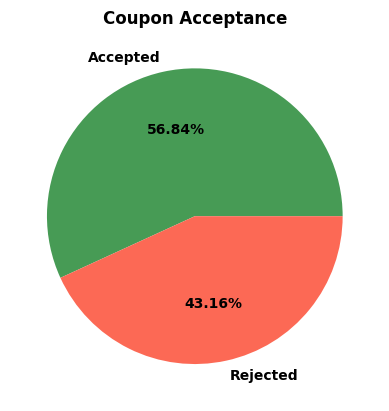

In [57]:
#Plot coupon acceptance and rejection ratios to visualize what the distribution will look like.
coupon_decision_counts = cleaned_data['Y'].value_counts().reindex([1, 0])
plt.pie(coupon_decision_counts, labels=['Accepted', 'Rejected'], colors=['#479B55', '#FC6955'], autopct='%1.2f%%', textprops={'fontweight': 'bold'})
plt.title('Coupon Acceptance', fontweight='bold')
plt.savefig('images/general_coupon_acceptance_rejection_rate.png')
plt.show()

5. Use a bar plot to visualize the `coupon` column.

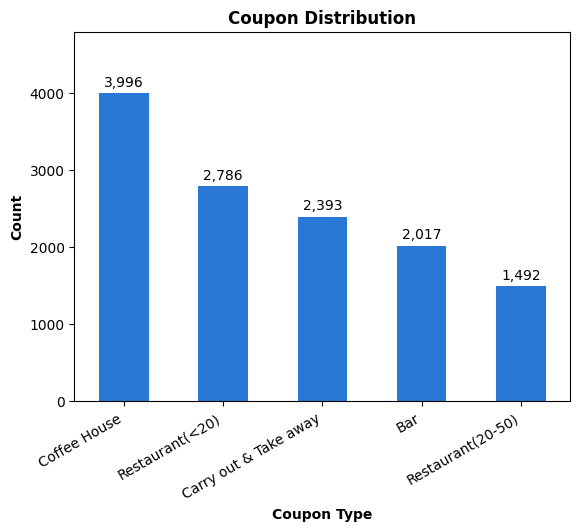

In [58]:
#Bar plot to visualize how coupon distribution is
coupon_counts = cleaned_data['coupon'].value_counts()
ax = coupon_counts.plot(kind='bar', color='#2a78d6')
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3)   # publish count on top of each bar
plt.ylim(0, coupon_counts.max() * 1.2)                     # increase width on top so the top label isn't cut off
plt.xlabel("Coupon Type", fontweight = "bold")
plt.ylabel("Count", fontweight = "bold")
plt.title("Coupon Distribution", fontweight = "bold")
plt.xticks(rotation=30, ha='right')
plt.tight_layout
plt.savefig('images/coupon_type_distribution.png')
plt.show()

6. Use a histogram to visualize the temperature column.

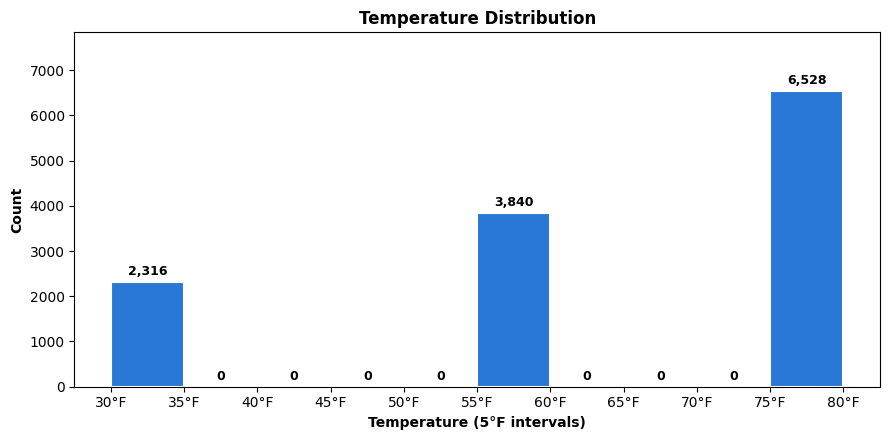

In [59]:
#Bar plot to visualize how temperature distribution is
fig, ax = plt.subplots(figsize=(9, 4.5))
counts, bins, bars = ax.hist(cleaned_data['temperature'],
                             color='#2a78d6', edgecolor='white', linewidth=1.5)

ax.bar_label(bars, labels=[f'{int(c):,}' for c in counts], padding=3, fontsize=9, fontweight = "bold")
ax.set_xticks(range(30, 85, 5), [f'{t}°F' for t in range(30, 85, 5)])   # tick at every 5°
ax.set_xlim(27.5, 82.5)
ax.set_ylim(0, counts.max() * 1.2)
ax.set_xlabel('Temperature (5°F intervals)', fontweight = "bold")
ax.set_ylabel('Count', fontweight = "bold")
ax.set_title('Temperature Distribution', fontweight = "bold")
plt.tight_layout()
plt.savefig('images/general_coupon_temperature_distribution.png')
plt.show()

**Investigating the Bar Coupons**

Now, we will lead you through an exploration of just the bar related coupons.  

1. Create a new `DataFrame` that contains just the bar coupons.


In [60]:

#Creates a new Dataframe called "bar_coupons_data" by filtering cleaned_data on column coupon = 'Bar'
bar_coupons_data = cleaned_data[cleaned_data['coupon']=='Bar']
bar_coupons_data.shape

(2017, 25)

2. What proportion of bar coupons were accepted?


In [61]:
#Total observations in the Bar Coupon dataset
Total_Bar_Coupon_Observations = bar_coupons_data.shape[0]
print(f'Total Observations: {Total_Bar_Coupon_Observations}')
#Total observations that chose to accept the Bar coupons:
Accept_Bar_Coupon = bar_coupons_data[bar_coupons_data['Y'] == 1]
print(f'Total Observations who accepted the coupon: {Accept_Bar_Coupon.shape[0]}')
#Total observations that chose to reject the Bar coupons:
Reject_Bar_Coupon = bar_coupons_data[bar_coupons_data['Y'] == 0]
print(f'Total Observations who rejected the coupon: {Reject_Bar_Coupon.shape[0]}')
#Method 1:
# The mean (average) of column 'Y' represents the proportion of Bar coupons being accepted
accepted_bar_coupons_ratio =  (bar_coupons_data['Y'].mean()* 100).round(2)
print(f"The acceptance percentage of the bar coupon was: {accepted_bar_coupons_ratio}"'%')

#Method 2:
#accepted_bar_coupons_ratio_2 =  round(((Accept_Bar_Coupon.shape[0] / Total_Bar_Coupon_Observations) * 100),2)
#print(f"The acceptance percentage of the bar coupon was {accepted_bar_coupons_ratio_2}")

Total Observations: 2017
Total Observations who accepted the coupon: 827
Total Observations who rejected the coupon: 1190
The acceptance percentage of the bar coupon was: 41.0%


**Plot a visualization to demonstrate Bar coupon acceptance and rejection ratios:**

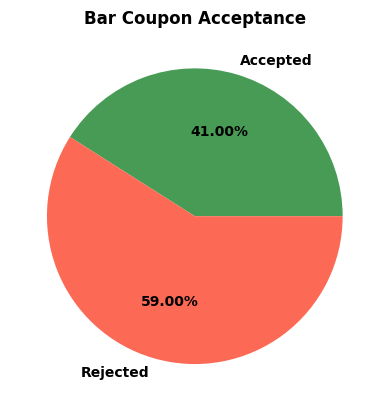

In [62]:
#Plot Bar coupon acceptance and rejection ratios to visualize what the distribution will look like.
bar_coupon_decision_counts = bar_coupons_data['Y'].value_counts().reindex([1, 0])
plt.pie(bar_coupon_decision_counts, labels=['Accepted', 'Rejected'], colors=['#479B55', '#FC6955'], autopct='%1.2f%%', textprops={'fontweight': 'bold'})
plt.title('Bar Coupon Acceptance', fontweight='bold')
plt.savefig('images/bar_coupon_acceptance_rejection_rate.png')
plt.show()

3. Compare the acceptance rate between those who went to a bar 3 or fewer times a month to those who went more.


In [63]:
#Define values that suggest bar visits are less than or equal to 3 times.
bar_3_times_or_less = ['never', 'less1', '1~3']
#Define values that suggest bar visits are greater than 3 times.
bar_more_than_3_times = ['4~8', 'gt8']

#creates a new dataframe "count_bar_3_times_or_less" which contains driver data who went to bar and visited bar 3 times or less
count_bar_3_times_or_less = bar_coupons_data[bar_coupons_data['Bar'].isin(bar_3_times_or_less)]
#creates a new dataframe "count_bar_more_than_3_times" which contains driver data who went to bar and visited bar more than 3 times
count_bar_more_than_3_times = bar_coupons_data[bar_coupons_data['Bar'].isin(bar_more_than_3_times)]

#Compute Coupon acceptance rate (in %) of a Bar Coupon by a driver who visits Bar less than or equal to 3 times
acceptance_rate_bar_3_times_or_less = round(((count_bar_3_times_or_less['Y'].mean()) * 100), 2)
acceptance_rate_bar_more_than_3_times = round(((count_bar_more_than_3_times['Y'].mean()) * 100), 2)

print(f'Coupon acceptance rate for those who went to a bar 3 or fewer times a month: {acceptance_rate_bar_3_times_or_less}%')
print(f'Coupon acceptance rate for those who went to a bar more than 3 times a month: {acceptance_rate_bar_more_than_3_times}%')

Coupon acceptance rate for those who went to a bar 3 or fewer times a month: 37.07%
Coupon acceptance rate for those who went to a bar more than 3 times a month: 76.88%


4. Compare the acceptance rate between drivers who go to a bar more than once a month and are over the age of 25 to the all others.  Is there a difference?


In [64]:
#print all values in "age" column
print('unique age values: ' + str(bar_coupons_data['age'].unique()))
#print all values in "Bar" column
print('unique bar visit values: ' + str(bar_coupons_data['Bar'].unique()))

#Define variable that contains values for bar visits more than once a month
bar_visit_more_than_once_a_month = ['1~3','gt8','4~8']
#Define variable that contains values for bar visits less than once a month
bar_visit_less_than_once_a_month = ['never', 'less1']
#Define variable that contains values for age over 25
age_over_25 = ['46', '26', '31', '41', '50plus', '36']
#Define variable that contains values for age under 25
age_under_25 = ['below21', '21']

#category_1 contains acceptance rate (in %) of drivers who goes to a bar more than once a month and are above 25 years old and have accepted the coupon.
category_1 = round(((bar_coupons_data.query("age in @age_over_25 and Bar in @bar_visit_more_than_once_a_month")["Y"].mean())* 100), 2)
#category_1_other contains acceptance rate (in %) of drivers who goes to a bar less than once a month and are below 25 years old and have accepted the coupon.
category_1_other = round(((bar_coupons_data.query("age in @age_under_25 or Bar in @bar_visit_less_than_once_a_month")["Y"].mean())* 100), 2)

#Print the acceptance rates in %
print(f'Coupon acceptance Rate for drivers who go to a bar more than once a month and are over the age of 25: {category_1}%')
print(f'Coupon acceptance Rate for drivers who go to a bar less than once a month and are under the age of 25: {category_1_other}%')

unique age values: ['21' '46' '26' '31' '41' '50plus' '36' 'below21']
unique bar visit values: ['never' 'less1' '1~3' 'gt8' '4~8']
Coupon acceptance Rate for drivers who go to a bar more than once a month and are over the age of 25: 69.52%
Coupon acceptance Rate for drivers who go to a bar less than once a month and are under the age of 25: 33.5%


5. Use the same process to compare the acceptance rate between drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry.


In [65]:
#we are referring bar_visit_more_than_once_a_month and bar_visit_less_than_once_a_month variables from the previous step.

#category_2 contains coupon acceptance rate (in %) from drives who go to bars more than once a month and had passgengers that were not a kid and had occupations other than farming, fishing, or forestry.
category_2 = round(((bar_coupons_data[
    (bar_coupons_data['Bar'].isin(bar_visit_more_than_once_a_month)) &
    (bar_coupons_data['occupation'] != 'Farming Fishing & Forestry') &
    (bar_coupons_data['passenger'] != 'Kid(s)')
]['Y'].mean())*100), 2)

#category_2_other contains coupon acceptance rate (in %) from drives who go to bars less than once a month and had passgengers who are Kid(s) and had occupations is farming, fishing, or forestry.
category_2_other = round(((bar_coupons_data[
    (bar_coupons_data['Bar'].isin(bar_visit_less_than_once_a_month)) &
    (bar_coupons_data['occupation'] == 'Farming Fishing & Forestry') &
    (bar_coupons_data['passenger'] == 'Kid(s)')]['Y'].mean())*100), 2)

print(f'Coupon Acceptance Rate for drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry: {category_2}%')
print(f'Coupon Acceptance Rate for drives who go to bars less than once a month and had passgengers who are Kid(s) and had occupations is farming, fishing, or forestry: {category_2_other}%')

Coupon Acceptance Rate for drivers who go to bars more than once a month and had passengers that were not a kid and had occupations other than farming, fishing, or forestry: 71.32%
Coupon Acceptance Rate for drives who go to bars less than once a month and had passgengers who are Kid(s) and had occupations is farming, fishing, or forestry: 33.33%


6. Compare the acceptance rates between those drivers who:

- go to bars more than once a month, had passengers that were not a kid, and were not widowed *OR*
- go to bars more than once a month and are under the age of 30 *OR*
- go to cheap restaurants more than 4 times a month and income is less than 50K.



In [66]:
#criteria_1 contains coupon acceptance rates for drivers who go to bars more than once a month, had passengers that were not a kid, and were not widowed
criteria_1 = round(((bar_coupons_data[
    (bar_coupons_data['Bar'].isin(['1~3','gt8','4~8'])) &
    (bar_coupons_data['maritalStatus'] != 'Widowed') &
    (bar_coupons_data['passenger'] != 'Kid(s)')]['Y'].mean())*100),2)
#criteria_2 contains coupon acceptance rates for drivers who go to bars more than once a month and are under the age of 30
criteria_2 = round(((bar_coupons_data[
    (bar_coupons_data['Bar'].isin(['1~3','gt8','4~8'])) &
    (bar_coupons_data['age'].isin(['below21','21','26']))]['Y'].mean())*100),2)
#criteria_3 contains coupon acceptance rates for drivers who go to cheap restaurants more than 4 times a month and income is less than 50K
criteria_3 = round(((bar_coupons_data[
    (bar_coupons_data['RestaurantLessThan20'].isin(['gt8','4~8'])) &
    (bar_coupons_data['income'].isin(['Less than $12500','$12500 - $24999', '$25000 - $37499', '$37500 - $49999']))]['Y'].mean())*100),2)

print(f'Acceptance Rate for Drivers who go to bars more than once a month, had passengers that were not a kid, and were not widowed: {criteria_1}%')
print(f'Acceptance Rate for Drivers who go to bars more than once a month and are under the age of 30: {criteria_2}%')
print(f'Acceptance Rate for Drivers who go to cheap restaurants more than 4 times a month and income is less than 50K: {criteria_3}%')

Acceptance Rate for Drivers who go to bars more than once a month, had passengers that were not a kid, and were not widowed: 71.32%
Acceptance Rate for Drivers who go to bars more than once a month and are under the age of 30: 72.17%
Acceptance Rate for Drivers who go to cheap restaurants more than 4 times a month and income is less than 50K: 45.35%


7.  Based on these observations, what do you hypothesize about drivers who accepted the bar coupons?

**Findings:**

*   Drivers who accept bar coupons are mainly people who already go to bars regularly. Only 41.0% of bar coupons were accepted and this compares poorly against 56.84% of the drivers who accepted coupons across all coupon types.

*   Drivers who go to bar atleast 3 or more times are most likely to accept bar coupons. The acceptance rate (in%) for this groups is 76.88% meaning 3 out of 4 people will accept the coupons if they are visiting the bar 3 or more times in a month.
*   Drivers who are over age 25 and visit bar atleast one time a month are mostly likely to accept Bar Coupons. The coupon acceptance rate (in %) for this group is 69.52%. This acceptance rate increases to 72.17% for drivers who are under 30 years of age.

*   Drivers who visit more than once a month and don't have a kid and not from farming, fishing, or forestry occupation are most likely to accept the coupon. The acceptance rate (in%) for this groups is 71.32% meaning nearly 3 out of 4 people will accept the coupons


*  Drivers who visit more than once a month and don't have a kid and not a widower are most likely to accept the coupon. The acceptance rate (in%) for this groups is 72.17% meaning nearly 3 out of 4 people will accept the coupons


**Hypothesis:**

*   Bar Visit Frequency: Bar visiting frequency is key influencer of whether the drivers will accept the coupon or not. This may be because regular visitors want to reduce what they already spend at bars by using coupons.


*   Age: Drivers under 30 accepted 48.9% of bar coupons, compared with 34.6% of drivers aged 30 and over, against an overall rate of 41.0%. The effect is strongest when youth combines with bar-going habits: drivers under 30 who visit bars more than once a month accepted 72.2%. This could indicate that younger drivers are more inclined to meet friends or family at bar, and so are more likely to take advantage of discount coupons.

*   Marital Status or Occupation: Nearly 3 out of 4 Drivers who visit bar more than once a month and do not have kids and are not widower or not working in farming, fishing or forestry occupation are most likely to accept coupons. This could indicate that drivers who are fathers to kids will find little time to engage in social activites or visit bars very often.




### Independent Investigation

Using the bar coupon example as motivation, you are to explore one of the other coupon groups and try to determine the characteristics of passengers who accept the coupons.  

# Investigating the Coffee Coupons:
I will be performing investigation using "Coffee House" coupons as it contains  >31% of the total records in the dataset

Create a new `DataFrame` that contains just the Coffee House coupons.

**Identify Coffee House coupon acceptance and rejection rates**

In [67]:
#create a new dataframe coffee_house_coupons_data that contains rows filtered by column "Coupon" and value "Coffee House"
coffee_house_coupons_data = cleaned_data[cleaned_data['coupon']=='Coffee House']
#create a new dataframe coffee_house_coupons_data that contains rows filtered by column "Coupon" and value "Coffee House" and drivers who accepted coupons
coffee_house_coupons_accepted_data = cleaned_data[(cleaned_data['coupon']=='Coffee House') & (cleaned_data['Y'] == 1)]
#create a new dataframe coffee_house_coupons_data that contains rows filtered by column "Coupon" and value "Coffee House" and drivers who rejected coupons
coffee_house_coupons_rejected_data = cleaned_data[(cleaned_data['coupon']=='Coffee House') & (cleaned_data['Y'] == 0)]

#Total drivers who were provided with a Coffee House Coupon
print(f'Total drivers who were provided with a Coffee House Coupon: {coffee_house_coupons_data.shape[0]}')

#Total drivers that chose to accept the Coffee House coupons:

print(f'Total drivers who accepted the coupon: {coffee_house_coupons_accepted_data.shape[0]}')
#Total drivers that chose to reject the Coffee House coupons:

print(f'Total drivers who rejected the coupon: {coffee_house_coupons_rejected_data.shape[0]}')
#Compute Coffee coupon acceptance rate (in %) and coupon rejection rate (in %)
accepted_coffee_house_coupons_ratio =  round(((coffee_house_coupons_accepted_data.shape[0] / coffee_house_coupons_data.shape[0]) * 100),2)
rejected_coffee_house_coupons_ratio =  round(((coffee_house_coupons_rejected_data.shape[0] / coffee_house_coupons_data.shape[0]) * 100),2)
print(f"The acceptance rate (in %) of the Coffee House coupon was {accepted_coffee_house_coupons_ratio}%")
print(f"The rejection rate (in %) of the Coffee House coupon was {rejected_coffee_house_coupons_ratio}%")


Total drivers who were provided with a Coffee House Coupon: 3996
Total drivers who accepted the coupon: 1995
Total drivers who rejected the coupon: 2001
The acceptance rate (in %) of the Coffee House coupon was 49.92%
The rejection rate (in %) of the Coffee House coupon was 50.08%


**Plot a visualization to represent Coffee House Coupon Acceptance Rates**

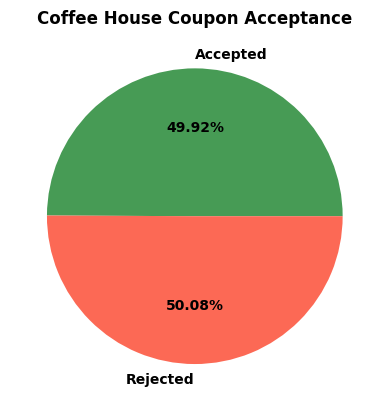

In [68]:
#Plot Coffee House coupon acceptance and rejection ratios to visualize what the distribution will look like.
coffee_house_coupons_decision_counts = coffee_house_coupons_data['Y'].value_counts().reindex([1, 0])
plt.pie(coffee_house_coupons_decision_counts, labels=['Accepted', 'Rejected'], colors=['#479B55', '#FC6955'], autopct='%1.2f%%', textprops={'fontweight': 'bold'})
plt.title('Coffee House Coupon Acceptance', fontweight='bold')
plt.savefig('images/coffee_house_coupon_acceptance_rejection_rate.png')
plt.show()

**Compare what Coffee House Coupon Acceptance Rates will look like based on different times of the day**

In [69]:
#Coffee House coupon acceptance rates against time.
time_order = ['7AM', '10AM', '2PM', '6PM', '10PM']
coffee_coupon_acceptance_time_summary = ((coffee_house_coupons_data.groupby('time')['Y'].mean())*100).round(2).reindex(time_order)
print("Coffee Coupon Acceptance rates (in %) against Time: ")
print(coffee_coupon_acceptance_time_summary)


Coffee Coupon Acceptance rates (in %) against Time: 
time
7AM     44.58
10AM    64.07
2PM     54.79
6PM     41.26
10PM    42.42
Name: Y, dtype: float64


**Identify the best time in the day that drivers accept a Coffee House Coupon**

In [70]:
#Identify what is the ideal time to attract drivers through Coffee House Coupons
coupon_acceptance_best_time = coffee_coupon_acceptance_time_summary.idxmax()
coupon_acceptance_best_time_percentage = coffee_coupon_acceptance_time_summary.max()
print(f"Highest acceptance rate for Coffee Coupon is at: {coupon_acceptance_best_time} with {coupon_acceptance_best_time_percentage}%")

Highest acceptance rate for Coffee Coupon is at: 10AM with 64.07%


**What does the coffee house coupon acceptance rate will look like for drivers who earn less than 50K**

In [71]:
#Total drivers who were provided with a Coffee House Coupon
Total_Coffee_House_Coupon = coffee_house_coupons_data.shape[0]
#Total drivers who accepted Coffee House Coupon
Accept_Coffee_House_Coupon = coffee_house_coupons_data[coffee_house_coupons_data['Y'] == 1]
print(f'Total drivers who were provided with a Coffee House Coupon: {Total_Coffee_House_Coupon}')
print(f'Total drivers who accepted the coupon: {Accept_Coffee_House_Coupon.shape[0]}')

#Filter data to identify drivers who earn less than 50K and have accepted the coupon
coupon_acceptance_under_50K = Accept_Coffee_House_Coupon[Accept_Coffee_House_Coupon['income'].isin(['Less than $12500','$12500 - $24999', '$25000 - $37499', '$37500 - $49999'])]
#Coffee Coupon Acceptance Rates (in %) for drivers who earn less than 50K
coupon_acceptance_rate_under_50K = round(((coupon_acceptance_under_50K.shape[0]/Accept_Coffee_House_Coupon.shape[0])*100),2)

print(f'Drivers coupon acceptance rate and income is less than 50K: {coupon_acceptance_rate_under_50K}%')

Total drivers who were provided with a Coffee House Coupon: 3996
Total drivers who accepted the coupon: 1995
Drivers coupon acceptance rate and income is less than 50K: 55.84%


**Compare Coffee Coupon acceptance rates for drivers based on age**

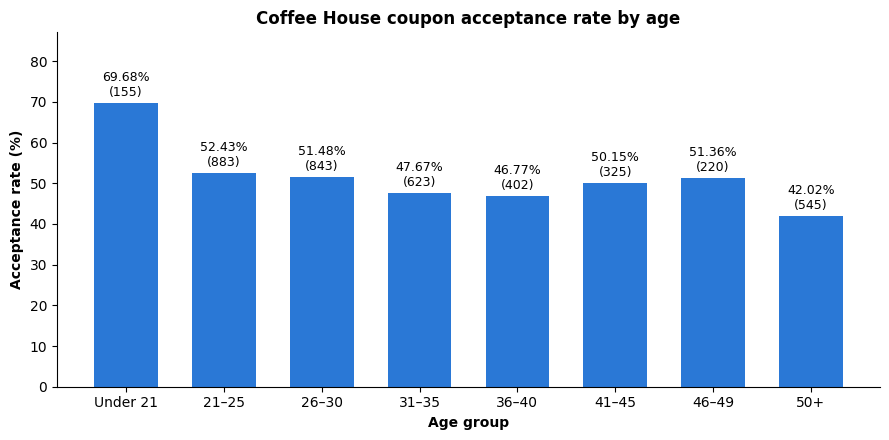

In [72]:
#Define variable that contains values for age
age_order  = ['below21', '21', '26', '31', '36', '41', '46', '50plus']
age_labels = ['Under 21', '21–25', '26–30', '31–35', '36–40', '41–45', '46–49', '50+']   # readable names, same order as age_order

#Define % of drivers who accepted the coupon grouped by age
age_summary = ((coffee_house_coupons_data.groupby('age')['Y'].mean())*100).round(2).reindex(age_order)
#Define count of drivers who accepted the coupon grouped by age
age_counts = coffee_house_coupons_data['age'].value_counts().reindex(age_order)   # coupons offered per age group

#Plot visualization using bar graph that demonstrate how the Coffee House coupon acceptance rates fare against various age groups.
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(age_labels, age_summary.values, color='#2a78d6', width=0.65)
ax.bar_label(bars, labels=[f'{p:.2f}%\n({n:,})' for p, n in zip(age_summary.values, age_counts.values)],
             padding=3, fontsize=9)
ax.set_ylim(0, age_summary.max() * 1.25)        # room for the labels
ax.set_xlabel('Age group', fontweight='bold')
ax.set_ylabel('Acceptance rate (%)', fontweight='bold')
ax.set_title('Coffee House coupon acceptance rate by age', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/coffee_hours_coupon_acceptance_rate_by_age.png')
plt.show()

**Compare Coffee Coupon acceptance rates for drivers based on temperature**

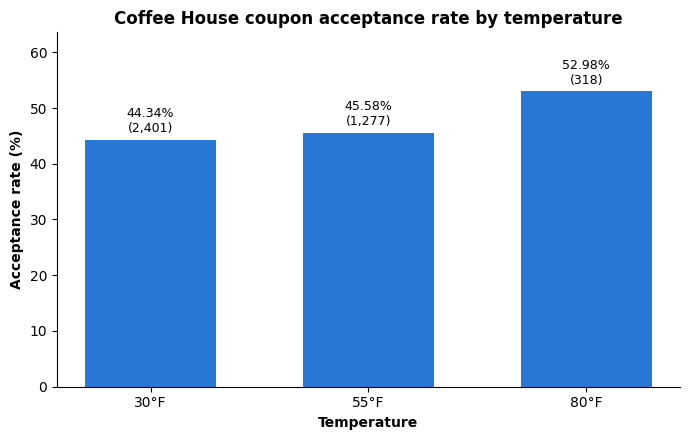

In [73]:
#Define variable that contains temperature values
temp_order = ['30', '55', '80']
#Define % of drivers who accepted the Coffee House coupon grouped by temperature
temp_summary = ((coffee_house_coupons_data.groupby('temperature')['Y'].mean())*100).round(2)
#Define count of drivers who accepted the Coffee House coupon grouped by temperature
temp_counts  = coffee_house_coupons_data['temperature'].value_counts()   # coupons offered per temperature
# Label formating the temperatures to '30°F', '55°F', '80°F'
temp_labels  = [f'{t}°F' for t in temp_order]
#Plot visualization using bar graph that demonstrate how the Coffee House coupon acceptance rates fare against various temperature.

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(temp_labels, temp_summary.values, color='#2a78d6', width=0.6)
ax.bar_label(bars, labels=[f'{p:.2f}%\n({n:,})' for p, n in zip(temp_summary.values, temp_counts.values)],
             padding=3, fontsize=9)
ax.set_ylim(0, temp_summary.max() * 1.2)
ax.set_xlabel('Temperature', fontweight='bold')
ax.set_ylabel('Acceptance rate (%)', fontweight='bold')
ax.set_title('Coffee House coupon acceptance rate by temperature', fontweight='bold')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/coffee_house_coupon_acceptance_rate_by_temperature.png')
plt.show()

**Compare Coupon Acceptance rate between Male and Female gender while taking maritalStatus into consideration**

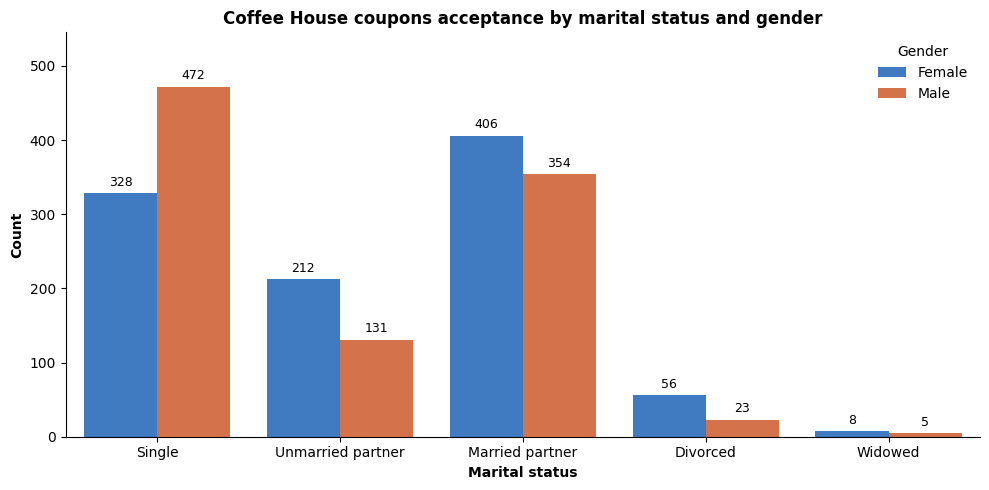

In [74]:
# Plot how Coffee House Coupon Acceptance fares between Male and Female gender when marital status is also taken into consideration.

#Define variable containing unique values from maritalStatus column
marital_order = ['Single', 'Unmarried partner', 'Married partner', 'Divorced', 'Widowed']
#Coffee House coupon acceptance data stored into accepted dataframe
coffe_house_coupon_accepted = coffee_house_coupons_data[coffee_house_coupons_data['Y'] == 1]

# Plot a Countplot visualization of accepted Coffee House coupons by marital status, split by gender (Female/Male). Each bar shows the number of accepted coupons for that marital status and gender.
fig, ax = plt.subplots(figsize=(10, 5))
sns.countplot(data=coffe_house_coupon_accepted, x='maritalStatus', hue='gender',
              order=marital_order, hue_order=['Female', 'Male'],
              palette={'Female': '#2a78d6', 'Male': '#eb6834'}, ax=ax)

for container in ax.containers:   # one container per gender
    ax.bar_label(container, fmt='{:,.0f}', padding=3, fontsize=9)

ax.set_ylim(0, ax.get_ylim()[1] * 1.1)               # room for the labels
ax.set_xlabel('Marital status', fontweight='bold')
ax.set_ylabel('Count', fontweight='bold')
ax.set_title('Coffee House coupons acceptance by marital status and gender', fontweight='bold')
ax.legend(title='Gender', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('images/coffe_House_coupon_acceptance_by_maritalStatus_gender.png')
plt.show()

**Based on these observations, what do you hypothesize about drivers who accepted the Coffee House coupons?**

**Findings:**


*   Coffee house coupons were accepted by drivers about half the time (49.92%). This is slightly lower than coupon acceptance rate across all coupon types (56.84%)
*   Drivers who visit Coffee House around 10 AM are most likely to accept coffee coupons. The acceptance rate (in%) for this category is 64.07%. The next best time is 2 PM where acceptance rate (in%) stood at 54.79%

*   Drivers under 21 are most likely to accept coffe house coupons. The acceptance rate for this category stood at 69.68% meaning nearly 7 out of 10 people who visit coffee house and are under age 21 will accept coupons.
*   Drivers who visit a Coffee House on a day with high temperature (80°F) are most likely to accept cofee house coupons. 52.98% of from this category accept the coupons. However, this is a minor factor as the value is just 3% more than coupon coupon acceptance rate.

*   Drivers who are male and single as well as female and have a married partner are most likely accept the coupons than others.



**Hypothesis:**



*   General: Coffee house coupons were accepted about half the time (49.92%), below the 56.84% rate across all coupon types. Based on other data points in findings, acceptance depends more on the driver's situation than on the offer itself.
*   Time: Time is an important factor to drive coupon acceptance. Coffee House coupon acceptance peaked when the coupon arrived at 10AM (64.07%) and 2PM (54.79%). This will indicate that acceptance rate rises during driver's spare time rather than busy time like commuting to or fro from work or at home.


*   Age: Age appears to matter in driving coffee house coupon acceptance. Drivers under age 21 are most likely to accept coupons and also majority of the users represented in this category are "Students". The adoption might be more due to social engagement with friends during or after school/college time.



